<a href="https://colab.research.google.com/github/Gitanjali2495/AD3142_Activity-1_Energy_Analyzer/blob/main/Smart_campus_Energy_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Campus Energy Analyzer & Predictor
### Using Simple Linear Regression

**Project Overview:**

This project analyzes the relationship between computer lab operating hours and electricity consumption using Simple Linear Regression.

The model learns from sample data and predicts electricity consumption based on the number of operating hours.

**Objectives:**
- Analyze electricity consumption data.
- Visualize relationships using graphs.
- Build a Linear Regression model.
- Evaluate model performance.
- Predict electricity consumption for new inputs.

**Technology Used:** Python, Pandas, NumPy, Matplotlib, Scikit-learn, Google Colab.

## 1. Importing Libraries

In this step, we import the required Python libraries for data analysis, visualization, model training and performance evaluation.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!



## 2. Dataset Loading

In this step, we load a real-world academic
building energy consumption dataset from
Mendeley Data.

The dataset contains hourly time information
and corresponding electricity consumption
in kWh.

This dataset is used to analyze the relationship
between time and electricity consumption.


In [25]:


import pandas as pd

# Load Excel dataset
df = pd.read_excel(
    "hourly load profile of NITPY.xlsx",
    sheet_name="Sheet1",
    header=None
)

# Rename electricity consumption column
df.columns = ["Electricity_Consumption"]

# Create hourly time column (1 to 8760)
df.insert(0, "Operating_Hours", range(1, len(df) + 1))

# Remove missing values
df = df.dropna()

print("Dataset Loaded Successfully!")
print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:", df.shape)


Dataset Loaded Successfully!

First 5 Records:
   Operating_Hours  Electricity_Consumption
0                1                     11.4
1                2                     11.1
2                3                     10.8
3                4                     10.5
4                5                     11.7

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Operating_Hours          8760 non-null   int64  
 1   Electricity_Consumption  8760 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 137.0 KB
None

Dataset Shape: (8760, 2)


## 3. Data Exploration and Analysis

Data exploration helps us understand the structure and quality of the dataset.

We check the number of records, data types, statistical summary, missing values and duplicate records.

In [26]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape:
(8760, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Operating_Hours          8760 non-null   int64  
 1   Electricity_Consumption  8760 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 137.0 KB
None

Statistical Summary:
       Operating_Hours  Electricity_Consumption
count      8760.000000              8760.000000
mean       4380.500000                22.750301
std        2528.938512                15.538975
min           1.000000                 3.220000
25%        2190.750000                10.917250
50%        4380.500000                18.971000
75%        6570.250000                29.607450
max        8760.000000                66.240000

Missing Values:
Operating_Hours            0
Electricity_Consumption    0
dtype: int64

Duplicate Records:
0


## 4. Data Visualization

Data visualization helps us understand the relationship between operating hours and electricity consumption.

A scatter plot is used to identify the direction and approximate linear pattern of the relationship.

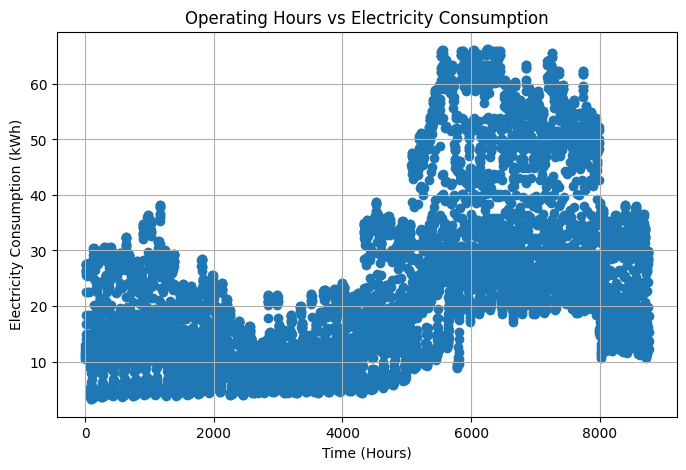

In [27]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Operating_Hours"],
    df["Electricity_Consumption"]
)

plt.xlabel("Time (Hours)")
plt.ylabel("Electricity Consumption (kWh)")

plt.title("Operating Hours vs Electricity Consumption")

plt.grid(True)
plt.show()

## 5. Feature Selection

In this step, we select the independent and dependent variables.

- X represents the independent variable (Operating Hours).
- y represents the dependent variable (Electricity Consumption).

The model uses X to predict y.

In [28]:

# Feature Selection

X = df[["Operating_Hours"]]

y = df["Electricity_Consumption"]

print("Input Variable:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Variable:
   Operating_Hours
0                1
1                2
2                3
3                4
4                5

Target Variable:
0    11.4
1    11.1
2    10.8
3    10.5
4    11.7
Name: Electricity_Consumption, dtype: float64


## 6. Train-Test Split

The dataset is divided into training and testing sets.

80% of the data is used to train the model, while 20% is used to evaluate its performance on unseen data.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (7008, 1)
Testing Data: (1752, 1)


## 7. Linear Regression Model Training

In this step, we create and train a Simple Linear Regression model using the training dataset.

The model learns the best-fit regression line by minimizing the squared prediction errors.

The regression equation is:

ŷ = mx + b

In [30]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

print("Slope:", model.coef_[0])

print("Intercept:", model.intercept_)

Linear Regression Model Trained Successfully!
Slope: 0.003284924818942043
Intercept: 8.352318328548499


## 8. Model Prediction

After training, the model predicts electricity consumption using the testing dataset.

We compare actual values with predicted values to understand the model's performance.

In [31]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison)

       Actual  Predicted
0     60.7200  28.249108
1     61.0300  26.606646
2     44.8040  28.032303
3     39.9750  33.564116
4      6.9650  19.258269
...       ...        ...
1747  12.0925  35.643474
1748   3.5880   8.684096
1749  25.9530  30.052532
1750   6.2550  14.212624
1751  61.9440  28.107856

[1752 rows x 2 columns]


## 9. Model Performance Evaluation

We evaluate the Linear Regression model using four performance metrics:

- MAE: Measures average absolute prediction error.
- MSE: Measures average squared prediction error.
- RMSE: Measures prediction error in the original target units.
- R² Score: Measures model fit compared with a mean-value baseline.

In [32]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Performance")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Model Performance
MAE: 10.498247050566537
MSE: 177.46234371650164
RMSE: 13.321499304376427
R2 Score: 0.253454013261575


## 10. Regression Line Visualization

In this step, we visualize the actual observations and the fitted regression line.

The graph helps us understand how well the model represents the relationship between the two variables.

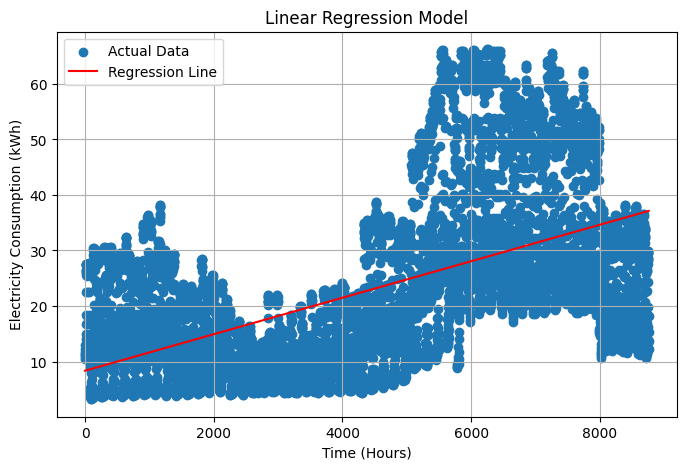

In [33]:
plt.figure(figsize=(8,5))

plt.scatter(
    X,
    y,
    label="Actual Data"
)

plt.plot(
    X,
    model.predict(X),
    color="red",
    label="Regression Line"
)

plt.xlabel("Time (Hours)")

plt.ylabel("Electricity Consumption (kWh)")

plt.title("Linear Regression Model")

plt.legend()

plt.grid(True)

plt.show()

## 11. Residual Analysis

Residuals represent the difference between actual and predicted values.

Residual analysis helps us inspect prediction errors and identify unusual patterns in the model.

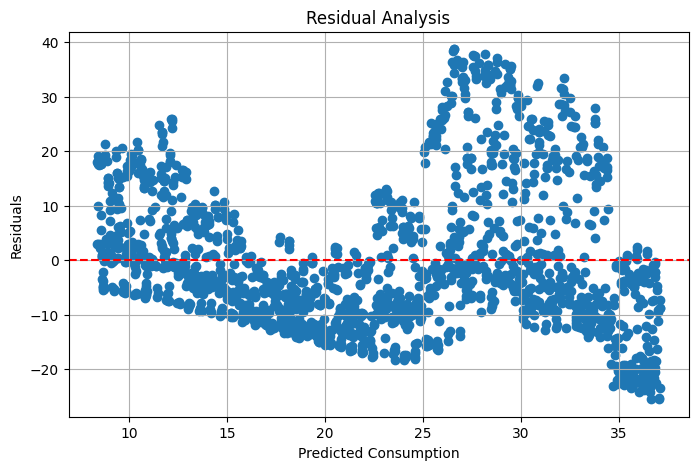

In [34]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Consumption")

plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.grid(True)

plt.show()

## 12. Interactive Electricity Consumption Prediction

This is the final stage of the project.

The user can enter the computer lab operating hours, and the trained Linear Regression model predicts the expected electricity consumption in kWh.

In [37]:
time_hours = float(input("Enter time in hours: "))

if time_hours < df["Operating_Hours"].min() or time_hours > df["Operating_Hours"].max():
    print("Warning: Prediction is outside the dataset range.")

prediction = model.predict(
    pd.DataFrame({
        "Operating_Hours": [time_hours]
    })
)

print("Time (Hours):", time_hours)

print(
    "Predicted Electricity Consumption:",
    round(prediction[0], 2),
    "kWh"
)


Enter time in hours: 1
Time (Hours): 1.0
Predicted Electricity Consumption: 8.36 kWh


## 13. Conclusion

The Smart Campus Energy Analyzer & Predictor successfully demonstrates the application of Simple Linear Regression.

The project analyzes the relationship between computer lab operating hours and electricity consumption. It trains a prediction model, evaluates its performance using different metrics, visualizes the regression line and predicts electricity consumption for new input values.

This project provides practical understanding of data analysis, visualization and supervised machine learning.